# Unidad II: Preparacion de Datos y Pipeline ETL
**Proyecto:** Clasificacion automatica y analisis morfologico de variedades de frijol  
**Estudiante:** Kevin Hernandez Trejo (23300950) | 10IDGS-G1  
**Materia:** Extraccion de Conocimiento en Bases de Datos (ECBD)  
**Docente:** Ing. Jose Luis Herrera Gallardo, MTI

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

raw_path = os.path.join("..", "data", "raw", "dry_bean_dataset", "DryBeanDataset", "Dry_Bean_Dataset.xlsx")
df_raw = pd.read_excel(raw_path)
print(f"Dimensiones iniciales: {df_raw.shape[0]} filas x {df_raw.shape[1]} columnas")
df_raw.head()

Dimensiones iniciales: 13611 filas x 17 columnas


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


### 1. Auditoria de Calidad: Valores Faltantes y Duplicados

In [2]:
print("Valores faltantes por columna:")
print(df_raw.isnull().sum())

dupes = df_raw.duplicated().sum()
print(f"\nFilas duplicadas exactas detectadas: {dupes}")
print("\nDuplicados desglosados por variedad:")
print(df_raw[df_raw.duplicated(keep=False)]["Class"].value_counts())

Valores faltantes por columna:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Filas duplicadas exactas detectadas: 68

Duplicados desglosados por variedad:
Class
HOROZ    136
Name: count, dtype: int64


### 2. Depuracion de Duplicados y Normalizacion de Columnas

In [3]:
df_clean = df_raw.drop_duplicates().copy()
df_clean = df_clean.rename(columns={"AspectRation": "AspectRatio", "roundness": "Roundness"})
print(f"Dimensiones tras deduplicacion y limpieza: {df_clean.shape[0]} filas x {df_clean.shape[1]} columnas")

out_path = os.path.join("..", "data", "processed", "dry_beans_cleaned.csv")
os.makedirs(os.path.dirname(out_path), exist_ok=True)
df_clean.to_csv(out_path, index=False)
print(f"Dataset curado exportado exitosamente a: {out_path}")

Dimensiones tras deduplicacion y limpieza: 13543 filas x 17 columnas


Dataset curado exportado exitosamente a: ..\data\processed\dry_beans_cleaned.csv


### 3. Distribucion de Instancias por Variedad (Post-ETL)

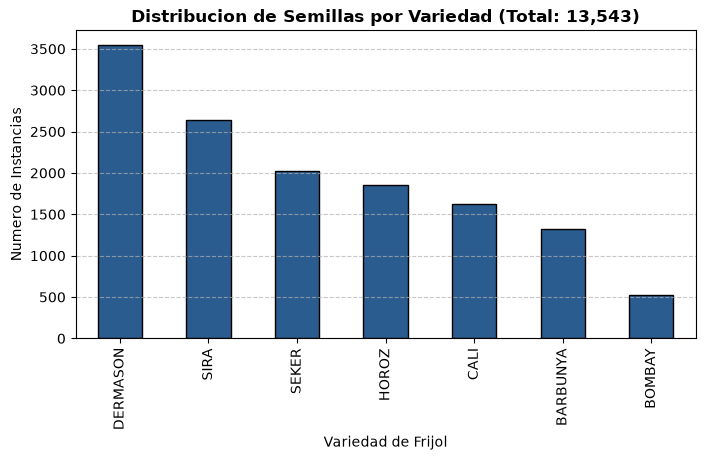

In [4]:
plt.figure(figsize=(8, 4))
df_clean["Class"].value_counts().plot(kind="bar", color="#2b5c8f", edgecolor="black")
plt.title("Distribucion de Semillas por Variedad (Total: 13,543)", fontsize=12, fontweight="bold")
plt.xlabel("Variedad de Frijol")
plt.ylabel("Numero de Instancias")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()